In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("/content/student_study_sleep_marks_dataset.csv")
df

,Study_Hours,Sleep_Hours,Marks
0,1,7,35
1,2,8,42
2,2,6,38
3,3,7,51
4,3,8,48
5,4,6,58
6,4,7,55
7,5,7,67
8,5,8,63
9,6,6,73


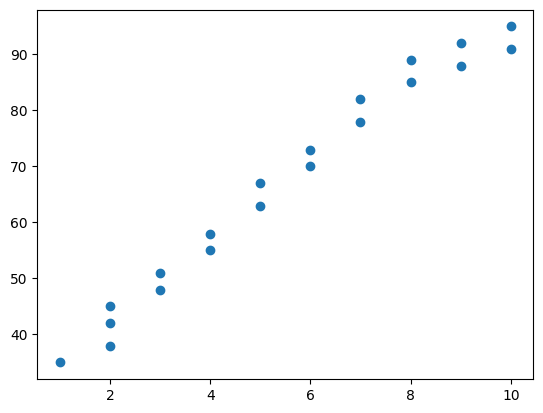

In [3]:
import matplotlib.pyplot as plt
plt.scatter(df["Study_Hours"], df["Marks"])

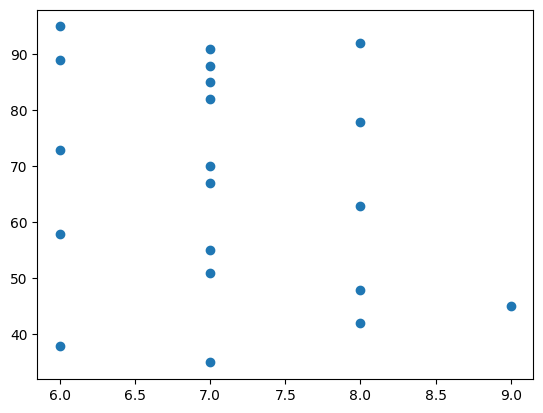

In [4]:
plt.scatter(df["Sleep_Hours"], df["Marks"])

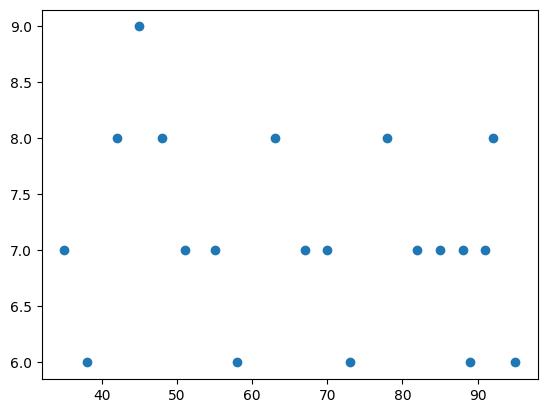

In [5]:
plt.scatter(df["Marks"], df["Sleep_Hours"])

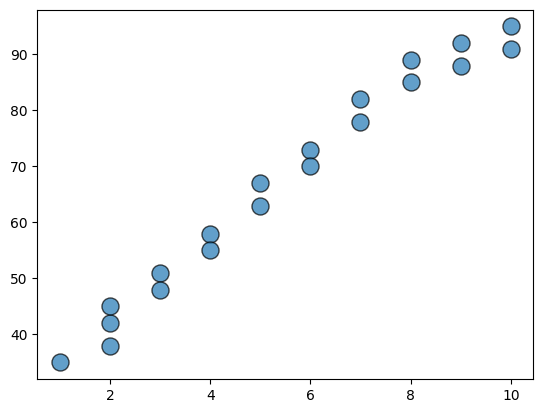

In [6]:
plt.scatter(df["Study_Hours"], df["Marks"], s = 150, edgecolors = "black", alpha = 0.7 )

In [7]:
df

,Study_Hours,Sleep_Hours,Marks
0,1,7,35
1,2,8,42
2,2,6,38
3,3,7,51
4,3,8,48
5,4,6,58
6,4,7,55
7,5,7,67
8,5,8,63
9,6,6,73


In [8]:
x = df["Study_Hours"]
y = df["Marks"]

In [9]:
x

,Study_Hours
0,1
1,2
2,2
3,3
4,3
5,4
6,4
7,5
8,5
9,6


In [10]:
y

,Marks
0,35
1,42
2,38
3,51
4,48
5,58
6,55
7,67
8,63
9,73


In [11]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 8)

In [12]:
x_train

,Study_Hours
18,10
4,3
12,7
2,2
13,8
1,2
16,9
0,1
14,8
19,2


In [14]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [17]:
model

LinearRegression()

In [20]:
model.fit(x_train.values.reshape(-1, 1), y_train)

LinearRegression()

In [21]:
print("Slope(m)" , model.coef_[0])
print("Intercept(c)" , model.intercept_)

Slope(m) 6.716457960644006
Intercept(c) 29.461538461538467


In [24]:
y_pred = model.predict(x_test.values.reshape(-1, 1))
y_pred

array([63.04382826, 76.47674419, 56.3273703 , 89.90966011])

In [25]:
x_test

,Study_Hours
7,5
11,7
6,4
15,9


In [26]:
y_test

,Marks
7,67
11,82
6,55
15,92


In [27]:
results = pd.DataFrame({
    "Actual" : y_test.values,
    "Predicted" : y_pred
})

In [28]:
results

,Actual,Predicted
0,67,63.043828
1,82,76.476744
2,55,56.327370
3,92,89.909660


In [29]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error" , mae)

Mean Absolute Error 3.224284436493738


In [30]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R2 Score", r2)

R2 Score 0.9344748341150271


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


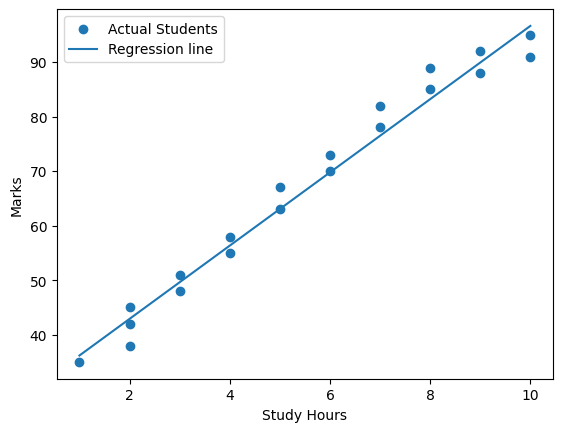

In [31]:
plot_data = df.sort_values("Study_Hours")

plt.scatter(df["Study_Hours"], df["Marks"], label = "Actual Students")

plt.plot(plot_data["Study_Hours"], model.predict(plot_data[["Study_Hours"]]), label = "Regression line")

plt.legend()

plt.xlabel("Study Hours")
plt.ylabel("Marks")

plt.show()

In [32]:
new_student = pd.DataFrame({
    "Study_Hours" : [5]
})

prediction = model.predict(new_student)

print("Predicted marks of New student", prediction)

Predicted marks of New student [63.04382826]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
